In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully.")

: 

In [ ]:
DATA_PATH = "../data/processed/ml_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (65499, 21)


,Patient,timestamp,glucose_value,glucose_lag_1,glucose_lag_2,glucose_lag_3,glucose_lag_6,glucose_change_5min,glucose_change_15min,meal_carbs,...,basal_value,temp_basal_value,exercise_duration,exercise_intensity,sleep_duration_hours,sleep_quality,finger_stick_value,hour,day_of_week,target_glucose_30min
0,540-ws-training,2027-05-19 11:36:29,76,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,71.0
1,540-ws-training,2027-05-19 11:41:29,72,76.0,0.0,0.0,0.0,-4.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,78.0
2,540-ws-training,2027-05-19 11:46:29,68,72.0,76.0,0.0,0.0,-4.0,0.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,90.0
3,540-ws-training,2027-05-19 11:51:29,65,68.0,72.0,76.0,0.0,-3.0,-11.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,99.0
4,540-ws-training,2027-05-19 11:56:29,63,65.0,68.0,72.0,0.0,-2.0,-9.0,0.0,...,0.95,0.0,0.0,0.0,0.0,0.0,80.0,11,2,110.0


In [3]:
lifestyle_columns = [
    "glucose_value",
    "glucose_change_5min",
    "glucose_change_15min",
    "meal_carbs",
    "bolus_dose",
    "basal_value",
    "temp_basal_value",
    "exercise_duration",
    "exercise_intensity",
    "sleep_duration_hours",
    "sleep_quality",
    "finger_stick_value",
    "target_glucose_30min"
]

df[lifestyle_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
glucose_value,65499.0,157.666270,60.870105,40.0,112.000000,149.0,193.000000,400.00
glucose_change_5min,65499.0,0.011542,7.199961,-286.0,-3.000000,0.0,3.000000,297.00
glucose_change_15min,65499.0,0.035023,16.480552,-301.0,-8.000000,-1.0,7.000000,310.00
meal_carbs,65499.0,54.564375,31.265287,0.0,30.000000,60.0,73.000000,162.00
bolus_dose,65499.0,6.766817,4.860390,0.0,2.900000,5.8,9.300000,25.00
basal_value,65499.0,1.067887,0.510255,0.4,0.450000,1.1,1.500000,2.00
temp_basal_value,65499.0,0.124615,0.384439,0.0,0.000000,0.0,0.000000,2.34
exercise_duration,65499.0,37.817127,52.848107,0.0,0.000000,0.0,61.000000,301.00
exercise_intensity,65499.0,3.232935,3.912407,0.0,0.000000,0.0,6.000000,10.00
sleep_duration_hours,65499.0,5.945071,3.209635,0.0,6.166667,7.0,7.933333,11.70


In [4]:
df["high_carb_meal"] = (df["meal_carbs"] >= 50).astype(int)

df["low_exercise"] = (df["exercise_duration"] == 0).astype(int)

df["poor_sleep"] = (df["sleep_quality"] <= 2).astype(int)

df["short_sleep"] = (df["sleep_duration_hours"] < 6).astype(int)

df["rapid_rise"] = (df["glucose_change_15min"] >= 15).astype(int)

df["rapid_fall"] = (df["glucose_change_15min"] <= -15).astype(int)

print("Lifestyle indicators created.")

Lifestyle indicators created.


In [5]:
df["lifestyle_risk_score"] = (
    df["high_carb_meal"]
    + df["low_exercise"]
    + df["poor_sleep"]
    + df["short_sleep"]
    + df["rapid_rise"]
    + df["rapid_fall"]
)

print(df["lifestyle_risk_score"].value_counts().sort_index())

lifestyle_risk_score
0    10124
1    12480
2    12573
3    18034
4    10677
5     1611
Name: count, dtype: int64


In [6]:
def classify_lifestyle(score):
    if score <= 1:
        return "Good"
    elif score <= 3:
        return "Moderate"
    else:
        return "Needs Attention"

df["lifestyle_status"] = df["lifestyle_risk_score"].apply(
    classify_lifestyle
)

df[[
    "Patient",
    "timestamp",
    "lifestyle_risk_score",
    "lifestyle_status"
]].head(10)

,Patient,timestamp,lifestyle_risk_score,lifestyle_status
0,540-ws-training,2027-05-19 11:36:29,3,Moderate
1,540-ws-training,2027-05-19 11:41:29,3,Moderate
2,540-ws-training,2027-05-19 11:46:29,3,Moderate
3,540-ws-training,2027-05-19 11:51:29,3,Moderate
4,540-ws-training,2027-05-19 11:56:29,3,Moderate
5,540-ws-training,2027-05-19 12:01:29,3,Moderate
6,540-ws-training,2027-05-19 12:06:29,3,Moderate
7,540-ws-training,2027-05-19 12:11:29,4,Needs Attention
8,540-ws-training,2027-05-19 12:16:29,4,Needs Attention
9,540-ws-training,2027-05-19 12:21:29,4,Needs Attention


In [7]:
lifestyle_analysis = (
    df.groupby("lifestyle_status")["target_glucose_30min"]
      .agg(["count", "mean", "std"])
      .reset_index()
)

lifestyle_analysis

,lifestyle_status,count,mean,std
0,Good,22604,158.891081,58.681875
1,Moderate,30607,157.251576,61.345564
2,Needs Attention,12288,156.818848,63.572770


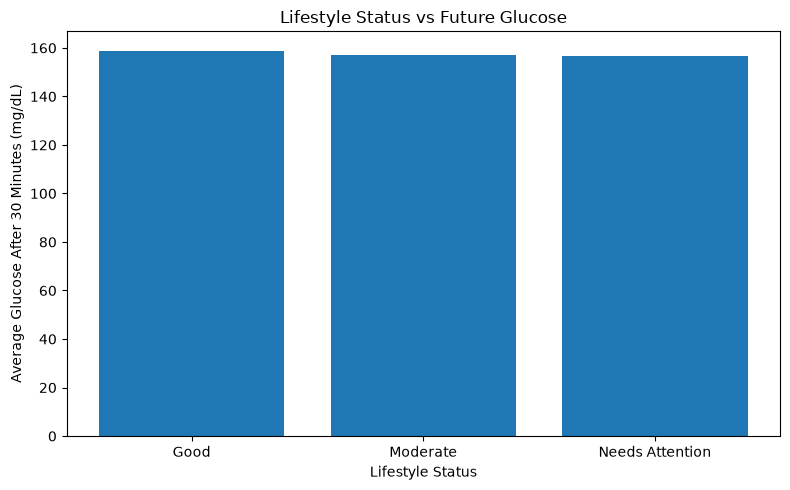

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    lifestyle_analysis["lifestyle_status"],
    lifestyle_analysis["mean"]
)

plt.xlabel("Lifestyle Status")
plt.ylabel("Average Glucose After 30 Minutes (mg/dL)")
plt.title("Lifestyle Status vs Future Glucose")

plt.tight_layout()
plt.show()